# 19. Numerical error

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 3, 12 and 18

**Reading:** Bevington & Robinson, Appendix A.3 · Press et al., *Numerical
Recipes*, ch. 1.1 and 5.7 · Higham, *Accuracy and Stability of Numerical
Algorithms*, ch. 1–2

Results today pass through a computer between the measurement and the
report, and the computer adds errors of its own. Three kinds matter:

* **rounding error**: real numbers are stored with about 16 significant
  digits, and every operation rounds;
* **truncation or discretisation error**: a derivative is replaced by a
  difference quotient, an integral by a sum, a differential equation by
  finite time steps;
* **sampling error** of Monte Carlo methods, treated in Chapter 10.

Usually all three are negligible, but not always, and unlike measurement
errors they are under the analyst's control. This chapter shows how to
recognise them, how to estimate them, and when they belong in the
uncertainty budget.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(119)

## 19.1 Floating-point numbers

A double-precision number has a 53-bit significand, so it represents a real
number with a relative rounding error of at most $u = 2^{-53} \approx
1.1\times10^{-16}$. The spacing of numbers just above 1 is
$\varepsilon = 2^{-52} \approx 2.2\times10^{-16}$, the **machine epsilon**
(Goldberg 1991). Most decimal fractions are not exact binary fractions, so
even entering data rounds them.

In [2]:
print(f"machine epsilon: {np.finfo(float).eps:.3e};  single precision: {np.finfo(np.float32).eps:.3e}")
print(f"0.1 + 0.2 == 0.3: {0.1 + 0.2 == 0.3};  difference {0.1 + 0.2 - 0.3:.2e}")
print(f"1e16 + 1 - 1e16 = {1e16 + 1 - 1e16}")

machine epsilon: 2.220e-16;  single precision: 1.192e-07
0.1 + 0.2 == 0.3: False;  difference 5.55e-17
1e16 + 1 - 1e16 = 0.0


A relative error of $10^{-16}$ in one operation is harmless. Trouble comes
when an algorithm *amplifies* it, and the commonest amplifier is the
subtraction of nearly equal numbers.

## 19.2 Cancellation: computing a variance

The variance of $N$ readings can be computed as

$$ s^2 = \frac{1}{N-1}\left[\sum x_i^2 - N\bar x^2\right]
  \qquad\text{or}\qquad
  s^2 = \frac{1}{N-1}\sum (x_i - \bar x)^2 . $$

The two are equal in exact arithmetic. The first needs only one pass through
the data and appears in many textbooks and pocket calculators. But if the
readings have a large common offset compared with their spread, say lengths
of about 1 m measured to 1 µm, the two terms in the bracket agree in nearly
all their digits, and their difference is mostly rounding error. The
relative error is about $u\,(\bar x/s)^2$: with $\bar x/s = 10^6$ only four
digits survive, and at $10^8$ none. The two-pass formula avoids the
cancellation, and **Welford's algorithm** (Welford 1962; Chan, Golub &
LeVeque 1983) achieves the same accuracy in one pass, updating the mean and
the sum of squared deviations reading by reading.

In [3]:
def var_textbook(x):
    n = x.size
    return (np.sum(x**2) - n * np.mean(x)**2) / (n - 1)

def var_two_pass(x):
    return np.sum((x - x.mean())**2) / (x.size - 1)

def var_welford(x):
    mean, m2 = 0.0, 0.0
    for k, xi in enumerate(x, start=1):
        d = xi - mean
        mean += d / k
        m2 += d * (xi - mean)
    return m2 / (x.size - 1)

offsets = np.logspace(0, 10, 21)
noise = rng.normal(0, 1, 1000)            # spread 1; the true variance is that of `noise`
v_true = np.var(noise, ddof=1)
rel_err = {"one-pass textbook": [], "two-pass": [], "Welford": []}
for off in offsets:
    x = off + noise
    for k, f in zip(rel_err, (var_textbook, var_two_pass, var_welford)):
        rel_err[k].append(abs(f(x) - v_true) / v_true)
rel_err = {k: np.maximum(np.array(v), 1e-17) for k, v in rel_err.items()}
for off in (1e3, 1e6, 1e8):
    j = np.argmin(np.abs(offsets - off))
    print(f"offset/spread = {offsets[j]:.0e}: relative error  textbook {rel_err['one-pass textbook'][j]:.1e},"
          f"  two-pass {rel_err['two-pass'][j]:.1e},  Welford {rel_err['Welford'][j]:.1e}")

offset/spread = 1e+03: relative error  textbook 3.3e-10,  two-pass 1.5e-15,  Welford 3.2e-14
offset/spread = 1e+06: relative error  textbook 1.7e-04,  two-pass 8.7e-13,  Welford 4.1e-12
offset/spread = 1e+08: relative error  textbook 1.0e+00,  two-pass 2.8e-10,  Welford 7.0e-10


The textbook formula loses accuracy as the square of the offset and is
useless beyond an offset of about $10^7$ times the spread, where it can even
return a negative variance. The other two are accurate to the level of the
rounding of the data themselves (the stored readings $x_i$ already carry
an absolute rounding error of about $u\,\bar x$, which limits any method). A
cheap safeguard for any formula: subtract a typical value, such as the first
reading, before computing.

## 19.3 Conditioning

Some problems amplify small changes of their input whatever the algorithm.
For a function $y = f(x)$, the **condition number**

$$ \kappa = \left|\frac{x\,f'(x)}{f(x)}\right| $$

is the factor by which a relative change of $x$ appears as a relative
change of $y$. It is exactly the elasticity of Section 18.1. A relative
rounding error of $u$ in the input therefore becomes about $\kappa u$ in
the output; but so does a relative *measurement* error, so an
ill-conditioned problem is sensitive to the data long before it is
sensitive to rounding.

For a linear system $A\mathbf p = \mathbf y$, as in a least-squares fit, the
condition number of the matrix plays the same role. Solving the normal
equations $(A^TA)\mathbf p = A^T\mathbf y$ *squares* it, because
$\kappa(A^TA) = \kappa(A)^2$. The cell fits a cubic to 21 annual readings,
with the year written in three ways.

In [4]:
from numpy.polynomial import Polynomial

years = np.arange(2000, 2021, dtype=float)
cubic = Polynomial([5, 0.3, -0.02, 0.001])          # true curve, in powers of (year - 2010)
y_data = cubic(years - 2010)                        # exact data, no noise

print("variable               cond(A)   cond(A^T A)   relative error of the coefficients")
print("                                                normal equations      lstsq")
for label, c, sc in (("year as is", 0, 1), ("year - 1900", 1900, 1),
                     ("year - 2010", 2010, 1), ("(year - 2010)/10", 2010, 10)):
    t = (years - c) / sc
    exact = cubic(Polynomial([c - 2010, sc])).coef                # true coefficients in powers of t
    A = np.vander(t, 4, increasing=True)
    p_ne = np.linalg.solve(A.T @ A, A.T @ y_data)                 # normal equations
    p_qr = np.linalg.lstsq(A, y_data, rcond=None)[0]              # orthogonal factorisation
    err = lambda q: np.linalg.norm(q - exact) / np.linalg.norm(exact)
    print(f"{label:18s}   {np.linalg.cond(A):8.1e}   {np.linalg.cond(A.T @ A):8.1e}      "
          f"{err(p_ne):8.0e}          {err(p_qr):8.0e}")

variable               cond(A)   cond(A^T A)   relative error of the coefficients
                                                normal equations      lstsq
year as is            3.8e+17    1.3e+26         2e+00             1e+00
year - 1900           1.0e+10    1.1e+20         7e-08             1e-11
year - 2010           6.5e+02    4.3e+05         2e-16             8e-16
(year - 2010)/10      7.5e+00    5.6e+01         7e-16             7e-16


The data lie exactly on a cubic, so any error in the coefficients is
numerical. With the raw years, the columns of $A$ ($1$, $t$, $t^2$, $t^3$
with $t \approx 2000$) are almost parallel, $\kappa(A)$ exceeds $1/u$, and
both methods return coefficients with no correct digits. Measured from
1900, the problem is ill-conditioned but solvable: `lstsq`, which
factorises $A$ without forming $A^TA$, keeps about eleven digits, while the
normal equations, with the squared condition number, keep about seven.
(The actual losses are smaller than the bound $\kappa u$ suggests, but they
grow with $\kappa$ as it does.) Centring and scaling the variable brings
both condition numbers down to harmless values, which is the numerical side
of the advice of Section 13.3. The rule: centre and scale before fitting,
and prefer an orthogonal factorisation to the normal equations.

## 19.4 Numerical derivatives: choosing the step

Linear propagation needs sensitivity coefficients, and `ep.jacobian` computes
them by central differences, $f'(x) \approx [f(x+h) - f(x-h)]/2h$. Two errors
compete. The **truncation error** of the formula is $h^2 |f'''|/6$ and
shrinks with $h$. The **rounding error**: $f(x\pm h)$ each carry an error of
about $u|f|$, which the division by $2h$ amplifies to about $u|f|/h$. The
total is smallest at

$$ h_\text{opt} \approx \left(\frac{3u|f|}{|f'''|}\right)^{1/3} \sim u^{1/3}|x| \approx 5\times10^{-6}|x| , $$

where the error is about $u^{2/3} \approx 10^{-11}$ relative. The forward
difference $[f(x+h) - f(x)]/h$ has a truncation error of order $h$, an
optimum near $u^{1/2}|x| \approx 10^{-8}|x|$, and a best accuracy of only
a few times $10^{-9}$ (Press et al., ch. 5.7). The cell differentiates
$f(x) = x\,e^{x}$ at $x = 1$ with steps from $10^{-14}$ to $10^{-1}$.

In [5]:
f = lambda x: x * np.exp(x)
x0 = 1.0
d_true = 2 * np.e
hs = np.logspace(-14, -1, 53)
err_c = np.abs((f(x0 + hs) - f(x0 - hs)) / (2 * hs) - d_true) / d_true
err_f = np.abs((f(x0 + hs) - f(x0)) / hs - d_true) / d_true
err_c = np.maximum(err_c, 1e-17); err_f = np.maximum(err_f, 1e-17)
print(f"central difference: best step {hs[np.argmin(err_c)]:.1e}, relative error {err_c.min():.1e};"
      f"  at h = 1e-5: {err_c[np.argmin(np.abs(hs - 1e-5))]:.1e}")
print(f"forward difference: best step {hs[np.argmin(err_f)]:.1e}, relative error {err_f.min():.1e}")
J = ep.jacobian(lambda x: x * np.exp(x), [x0])[0, 0]
print(f"ep.jacobian (relative step 1e-5): relative error {abs(J - d_true) / d_true:.1e}")

central difference: best step 3.2e-06, relative error 1.2e-11;  at h = 1e-5: 3.8e-11
forward difference: best step 1.0e-08, relative error 2.4e-09
ep.jacobian (relative step 1e-5): relative error 3.8e-11


The default relative step $10^{-5}$ of `ep.jacobian` sits at the bottom of
the central-difference curve, with an error near $10^{-11}$, far below any
measurement uncertainty. Too small a step is worse than too large: at
$h = 10^{-13}$ the derivative has only three or four correct digits. If a
model is itself computed numerically, for example by an iterative solver
with a tolerance of $10^{-8}$, then $u$ in the formula is replaced by that
tolerance, and the optimal step becomes much larger.

## 19.5 Discretisation error and Richardson extrapolation

A quantity computed with a step $h$ (a time step, a grid spacing, a number
of quadrature points) carries a discretisation error that, for a method of
order $p$, behaves as $E(h) \approx C h^p$ for small $h$. Results with two
steps then give an estimate of the error, without knowing the exact answer
(Richardson 1911):

$$ f_\text{exact} \approx f_h + \frac{f_h - f_{2h}}{2^p - 1} , \qquad
   E(h) \approx \frac{f_h - f_{2h}}{2^p - 1} . $$

With three steps $h, 2h, 4h$, the **observed order**
$p = \log_2[(f_{4h} - f_{2h})/(f_{2h} - f_h)]$ checks that $h$ is small
enough for the asymptotic form to hold. This procedure, with a safety
factor, is the basis of the *grid convergence index* used to report
discretisation uncertainty in computational engineering (Roache 1998).

The example integrates the equation of a pendulum released from 120°,
$\ddot\theta = -(g/L)\sin\theta$ with $g/L = 1$, up to $t = 10$, with the
classical fourth-order Runge–Kutta method (RK4) and with the first-order
Euler method, and examines the computed angle at the end. The reference
answer comes from RK4 with a very small step.

In [6]:
def rhs(s):
    return np.array([s[1], -np.sin(s[0])])

def integrate(step, h, t_end=10.0, s0=(np.radians(120), 0.0)):
    n = int(round(t_end / h))
    s = np.array(s0, float)
    for _ in range(n):
        s = step(s, h)
    return s

def euler(s, h):
    return s + h * rhs(s)

def rk4(s, h):
    k1 = rhs(s); k2 = rhs(s + h / 2 * k1); k3 = rhs(s + h / 2 * k2); k4 = rhs(s + h * k3)
    return s + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

theta_ref = integrate(rk4, 1e-4)[0]
steps = 0.4 / 2.0**np.arange(0, 8)
theta = {"RK4": np.array([integrate(rk4, h)[0] for h in steps]),
         "Euler": np.array([integrate(euler, h)[0] for h in steps[2:]] + [integrate(euler, h)[0] for h in steps[-1] / 2.0**np.arange(1, 5)])}
h_euler = np.r_[steps[2:], steps[-1] / 2.0**np.arange(1, 5)]

print(f"reference angle at t = 10: {theta_ref:.10f} rad")
print("  RK4:   h        theta(10)       true error    Richardson estimate   observed order")
for i in range(2, steps.size):
    p_obs = ep.observed_order(theta["RK4"][i], theta["RK4"][i - 1], theta["RK4"][i - 2])
    _, e_est = ep.richardson(theta["RK4"][i], theta["RK4"][i - 1], 4)
    print(f"      {steps[i]:.4f}   {theta['RK4'][i]:.10f}   {abs(theta['RK4'][i] - theta_ref):.2e}      {e_est:.2e}"
          f"            {p_obs:.2f}")
i = h_euler.size - 1
p_obs = ep.observed_order(theta["Euler"][i], theta["Euler"][i - 1], theta["Euler"][i - 2])
_, e_est = ep.richardson(theta["Euler"][i], theta["Euler"][i - 1], 1)
print(f"  Euler: h = {h_euler[i]:.5f}: true error {abs(theta['Euler'][i] - theta_ref):.2e},"
      f" Richardson estimate {e_est:.2e}, observed order {p_obs:.2f}")

reference angle at t = 10: 1.2317796575 rad
  RK4:   h        theta(10)       true error    Richardson estimate   observed order
      0.1000   1.2317805945   9.37e-07      2.85e-06            5.75
      0.0500   1.2317798287   1.71e-07      5.11e-08            5.80
      0.0250   1.2317796718   1.42e-08      1.05e-08            2.29
      0.0125   1.2317796585   9.99e-10      8.82e-10            3.57
      0.0063   1.2317796576   6.60e-11      6.22e-11            3.83
      0.0031   1.2317796576   4.36e-12      4.11e-12            3.92
  Euler: h = 0.00020: true error 4.78e-03, Richardson estimate 4.78e-03, observed order 1.00


Once the step is small enough for the observed order to settle near 4,
the Richardson estimate agrees with the true error to within about 10 %,
so the error of a computation can be estimated *from the computation
itself*. At the coarser steps the observed order is erratic (here because
the error of $\theta(10)$ passes through zero as $h$ changes), and then the
estimate cannot be trusted. Euler's method, of order 1, needs a step 500
times smaller than RK4 at $h = 0.1$, and still has an error about 5000 times
larger.

## 19.6 Long integrations: what the error does over time

For long simulations, as in the molecular dynamics of Chapter 23, the size
of the error after one step matters less than how it accumulates. The
total energy $E = \tfrac12\dot\theta^2 - \cos\theta$ of the pendulum should be
constant. The cell follows it over 1000 time units (about 140 periods) with
Euler, RK4, and the **velocity Verlet** method, which is only second order
but *symplectic*: it exactly conserves a slightly perturbed energy, so the
error of $E$ oscillates instead of growing (Hairer, Lubich & Wanner 2006).

In [7]:
def verlet(s, h):
    v_half = s[1] + h / 2 * (-np.sin(s[0]))
    th = s[0] + h * v_half
    return np.array([th, v_half + h / 2 * (-np.sin(th))])

def energy(s):
    return 0.5 * s[1]**2 - np.cos(s[0])

h_long, t_long = 0.1, 1000.0
n_long = int(t_long / h_long)
drift = {}
runs = (("Euler", euler, h_long), ("RK4", rk4, h_long),
        ("Verlet", verlet, h_long), ("Verlet, h/4", verlet, h_long / 4))
t_axis = {}
for name, step, h in runs:
    n = int(round(t_long / h))
    st = np.array([np.radians(120), 0.0]); E0 = energy(st)
    e = np.empty(n)
    for k in range(n):
        st = step(st, h)
        e[k] = energy(st) - E0
    drift[name], t_axis[name] = e, h * np.arange(1, n + 1)
    late = np.abs(e[t_axis[name] > 900]).max()
    print(f"{name:12s} (h = {h:.3f}): energy error after 10, 100, 1000 time units: "
          + ", ".join(f"{e[int(round(T / h)) - 1]:+.1e}" for T in (10, 100, 1000))
          + f";  largest |error| over the last 100 units {late:.1e}")

Euler        (h = 0.100): energy error after 10, 100, 1000 time units: +5.8e-01, +4.8e+00, +4.8e+01;  largest |error| over the last 100 units 4.8e+01
RK4          (h = 0.100): energy error after 10, 100, 1000 time units: -1.7e-06, -1.1e-05, -1.1e-04;  largest |error| over the last 100 units 1.1e-04
Verlet       (h = 0.100): energy error after 10, 100, 1000 time units: -4.1e-04, +1.9e-04, +8.3e-05;  largest |error| over the last 100 units 2.8e-03


Verlet, h/4  (h = 0.025): energy error after 10, 100, 1000 time units: -2.5e-05, +1.2e-05, +8.7e-06;  largest |error| over the last 100 units 1.8e-04


Euler's energy error grows without bound; with this step the energy soon
exceeds the value needed to swing over the top, so the simulated pendulum
rotates instead of oscillating. RK4 is very accurate, but its energy error
grows steadily, in proportion to the elapsed time. The Verlet error with
the same step is larger at first but does not grow: it oscillates within a
fixed band. RK4 evaluates the force four times per step and Verlet once, so
the fair comparison is with Verlet at a quarter of the step. Its band is
still slightly wider than RK4's error after 1000 time units, but RK4's
error grows in proportion to time, so it overtakes the band after roughly
1600 units and keeps growing, while the Verlet error never does. Molecular
dynamics runs last millions of steps. For long simulations the *structure* of the error
matters more than its order, which is why molecular dynamics codes use
Verlet-type integrators, and why a drift of a conserved energy is the
standard diagnostic of numerical error in such simulations.

## 19.7 Numerical error in the uncertainty budget

Numerical errors are treated like any other source of uncertainty
(Chapter 18):

1. Estimate them: by repeating the computation with a halved step
   (Richardson), a tighter tolerance, higher precision, or a different
   algorithm, or, for Monte Carlo, from the sampling error (Section 10.4).
2. If an estimate is below about a tenth of the combined measurement
   uncertainty, it adds less than 0.5 % in quadrature: state that it was
   checked and neglect it.
3. Otherwise, reduce it (it is usually cheap to do so), or include it as a
   Type B term. A discretisation error estimated by Richardson is a bias
   of known sign, so correct for it where possible and include the
   uncertainty of the correction.

A computed result whose numerical error has not been checked is, strictly,
a result of unknown uncertainty.

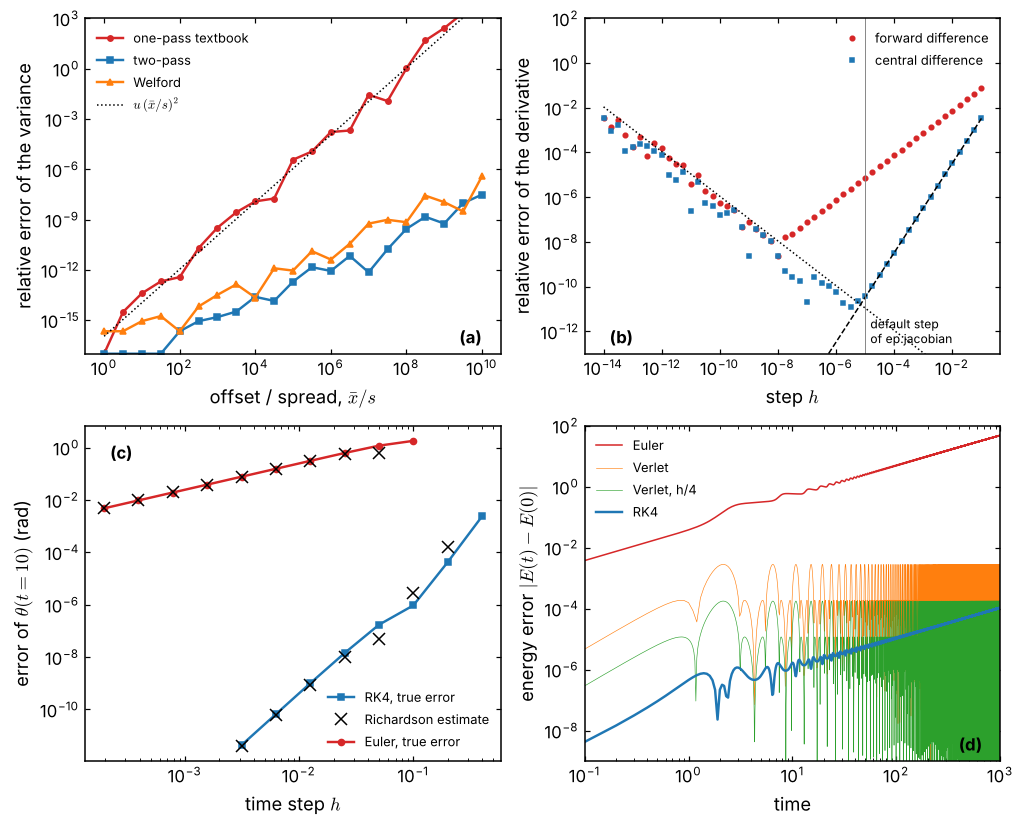

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
for (k, v), c, mk in zip(rel_err.items(), ("C3", "C0", "C1"), ("o", "s", "^")):
    ax.loglog(offsets, v, mk + "-", ms=3.5, color=c, label=k)
ax.loglog(offsets, 1.1e-16 * offsets**2, "k:", lw=1, label=r"$u\,(\bar x/s)^2$")
ax.set_xlabel(r"offset / spread, $\bar x/s$"); ax.set_ylabel("relative error of the variance")
ax.set_ylim(1e-17, 1e3); ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(a)", x=0.9, y=0.08)

ax = axes[0, 1]
ax.loglog(hs, err_f, "o", ms=3, color="C3", label="forward difference")
ax.loglog(hs, err_c, "s", ms=3, color="C0", label="central difference")
ax.loglog(hs, 1.1e-16 / hs, "k:", lw=1)
ax.loglog(hs, hs**2 * 4 * np.e / 6 / d_true, "k--", lw=1)
ax.axvline(1e-5, color="0.5", lw=0.6)
ax.text(1.5e-5, 3e-13, "default step\nof ep.jacobian", fontsize=8)
ax.set_xlabel("step $h$"); ax.set_ylabel("relative error of the derivative")
ax.set_ylim(1e-13, 1e2); ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(b)", x=0.06, y=0.08)

ax = axes[1, 0]
ax.loglog(steps, np.abs(theta["RK4"] - theta_ref), "s-", ms=4, color="C0", label="RK4, true error")
rk_est = [ep.richardson(theta["RK4"][i], theta["RK4"][i - 1], 4)[1] for i in range(1, steps.size)]
ax.loglog(steps[1:], rk_est, "x", ms=8, color="k", label="Richardson estimate")
ax.loglog(h_euler, np.abs(theta["Euler"] - theta_ref), "o-", ms=4, color="C3", label="Euler, true error")
eu_est = [ep.richardson(theta["Euler"][i], theta["Euler"][i - 1], 1)[1] for i in range(1, h_euler.size)]
ax.loglog(h_euler[1:], eu_est, "x", ms=8, color="k")
ax.set_xlabel("time step $h$"); ax.set_ylabel(r"error of $\theta(t = 10)$ (rad)")
ax.legend(loc="lower right", fontsize=8.5); ep.panel_label(ax, "(c)", x=0.06)

ax = axes[1, 1]
for name, c, lw in (("Euler", "C3", 1.0), ("Verlet", "C1", 0.4), ("Verlet, h/4", "C2", 0.4), ("RK4", "C0", 1.6)):
    ax.loglog(t_axis[name], np.abs(drift[name]), color=c, lw=lw, label=name)
ax.set_xlabel("time"); ax.set_ylabel("energy error $|E(t) - E(0)|$")
ax.set_xlim(0.1, 1000); ax.set_ylim(1e-9, 1e2); ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(d)", x=0.9, y=0.08)
plt.show()

**(a)** Relative error of the sample variance of 1000 readings against the
ratio of their common offset to their spread (dotted: the estimate
$u(\bar x/s)^2$). **(b)** Error of numerical derivatives of $x e^x$ at
$x = 1$; dotted: rounding error $u/h$; dashed: truncation error of the
central difference. **(c)** Error of a pendulum integration against the time
step, with Richardson estimates (crosses). **(d)** Error of the energy over
long integrations with $h = 0.1$, and with Verlet at $h = 0.025$, which costs
the same number of force evaluations as RK4 at $h = 0.1$.

## Summary

* Rounding is harmless until an algorithm amplifies it; subtraction of
  nearly equal numbers is the usual amplifier. Compute variances with a
  two-pass or Welford algorithm, or after subtracting an offset.
* The condition number of a problem is the elasticity of its output; it
  amplifies rounding and measurement errors alike. Centre and scale
  variables before fitting, and avoid the normal equations when the
  matrix is ill-conditioned.
* Central differences with a relative step near $10^{-5}$ give derivatives
  accurate to about $10^{-11}$; much smaller steps are worse.
* Estimate discretisation error by halving the step; check the observed
  order before trusting the Richardson estimate.
* Over long integrations, the structure of the error (bounded or
  drifting) matters more than its order.
* Numerical error is a term in the budget like any other: estimate it, and
  neglect it only once it is shown to be small.

## References

* T. F. Chan, G. H. Golub and R. J. LeVeque, "Algorithms for computing the
  sample variance: analysis and recommendations", *Am. Stat.* **37**, 242
  (1983).
* D. Goldberg, "What every computer scientist should know about
  floating-point arithmetic", *ACM Comput. Surv.* **23**, 5 (1991).
* E. Hairer, C. Lubich and G. Wanner, *Geometric Numerical Integration*,
  2nd ed. (Springer, 2006).
* N. J. Higham, *Accuracy and Stability of Numerical Algorithms*, 2nd ed.
  (SIAM, 2002).
* W. H. Press, S. A. Teukolsky, W. T. Vetterling and B. P. Flannery,
  *Numerical Recipes*, 3rd ed. (Cambridge University Press, 2007).
* L. F. Richardson, "The approximate arithmetical solution by finite
  differences of physical problems involving differential equations, with an
  application to the stresses in a masonry dam", *Phil. Trans. R. Soc. Lond.
  A* **210**, 307 (1911).
* P. J. Roache, *Verification and Validation in Computational Science and
  Engineering* (Hermosa, 1998).
* B. P. Welford, "Note on a method for calculating corrected sums of squares
  and products", *Technometrics* **4**, 419 (1962).

## Exercises

1. Repeat the variance comparison in single precision (`np.float32`). At
   what offset does the textbook formula fail now?
2. Show that the condition number of $f(x) = x - 1$ near $x = 1$ is
   $|x/(x - 1)|$, and relate this to the cancellation of Section 19.2.
3. Derive $h_\text{opt}$ for the central difference, and the corresponding
   result for the forward difference.
4. Use Richardson extrapolation on the RK4 results to improve
   $\theta(10)$, and estimate the error of the extrapolated value.
5. In the long integration, halve the time step. By what factor does the
   energy error of each method change, and does this match its order?

---

**Previous:** [18. Sensitivity analysis and uncertainty budgets](18_sensitivity_analysis_and_budgets.ipynb) &nbsp;·&nbsp; **Next:** [20. Physics: the acceleration of gravity from a pendulum](../part5_examples/20_pendulum_g.ipynb)